In [ ]:
import time
import h5py
import os
import numpy as np
import matplotlib.pyplot as plt
import sys
sys.path.append('/sdf/home/j/jwang343/rix101231825_Fe_L_edge/results/Jeff/DataAcceleratorChemRIXS/src/')

from chemrixs.average import Average
from chemrixs.smalldata import SmallData
from chemrixs.process import Reduced
from chemrixs.utils import *
from pathlib import Path
# %matplotlib widget 

In [ ]:
os.makedirs('proc', exist_ok=True)
os.makedirs('avg', exist_ok=True)
os.makedirs('figs', exist_ok=True)

FileNotFoundError: [Errno 2] No such file or directory

In [ ]:
base_folder =  '/sdf/data/lcls/ds/rix/'
proc_folder = './proc/'

bgrun = 86
mono_runs=[112,114,115,116,117,118,119,120,121,122,123,127,129,138,139,140,141,143,145]
delay_runs = [61, 62, 63, 64, 65]

exp = 'rix101231825'


fyaml = '../roi_input.yml'

bgname = f'{base_folder}/{exp}/hdf5/smalldata/{exp}_Run{bgrun:04d}.h5'
bgyaml = '../BGroi_input.yml'

avg = Average(mono_runs, proc_path = './proc/Run', avg = 'mean', output_path = f'avg/{mono_runs[0]}_to_{mono_runs[-1]}.h5',
             raw_path = f'{base_folder}/{exp}/hdf5/smalldata/{exp}_Run' , bgpath = bgname, fyaml=fyaml, bgyaml=bgyaml, 
             save= True,norm = True)

avg.plot_svls2D(figsize=(12,4),savefig=True)
avg.plot_svls1D(figsize=(12,4))


112
setting up properties
dataset prop <functools.cached_property object at 0x7f56a6c88750>
dataset prop <functools.cached_property object at 0x7f56a555a090>
dataset prop <functools.cached_property object at 0x7f56a535e950>
dataset prop <functools.cached_property object at 0x7f56a5490890>
dataset prop <functools.cached_property object at 0x7f56a5565f90>
dataset prop <functools.cached_property object at 0x7f56a54137d0>
dataset prop <functools.cached_property object at 0x7f56a5410450>
dataset prop <functools.cached_property object at 0x7f56a842ded0>
86
setting up properties
dataset prop <functools.cached_property object at 0x7f56a53a8dd0>
dataset prop <functools.cached_property object at 0x7f56a53a8290>
dataset prop <functools.cached_property object at 0x7f56a53aa6d0>
dataset prop <functools.cached_property object at 0x7f56a53a8e50>
dataset prop <functools.cached_property object at 0x7f56a53ab790>
dataset prop <functools.cached_property object at 0x7f56a53ab810>
scanvariable is unkown, b

FileNotFoundError: [Errno 2] Unable to synchronously create file (unable to open file: name = './proc/Run0112.h5', errno = 2, error message = 'No such file or directory', flags = 13, o_flags = 242)

In [9]:
import yaml
# --- config ---
base = '/sdf/data/lcls/ds/rix/'
exp  = 'rix101231825'
run  = 112
fyaml_path = '../roi_input.yml'         # swap to ferufe/roi_input_ferufe.yml if needed
n_show     = -1                       # subsample for speed
fname = f'{base}/{exp}/hdf5/smalldata/{exp}_Run{run:04d}.h5'

proc_name = './proc/Run0112.h5'

with open(fyaml_path) as f:
    cfg = yaml.safe_load(f)
    fim0_cfg = cfg['fim0']; fim1_cfg = cfg['fim1']

with h5py.File(proc_name, 'r') as h5:
    print(h5.keys())
    print(h5['axis_svls_off_mean'].shape)
    
    
print(avg.average['PFY_on_mean'].shape)

<KeysViewHDF5 ['axis_svls_off_mean', 'axis_svls_off_std', 'axis_svls_off_sum', 'axis_svls_on_mean', 'axis_svls_on_std', 'axis_svls_on_sum', 'counts_off', 'counts_on', 'scanvar_off', 'scanvar_on']>
(39, 796)
(39,)


In [4]:
avg_name = './avg/Run0112to145.h5'
with h5py.File(avg_name, 'r') as h5:
    print(h5.keys())

FileNotFoundError: [Errno 2] Unable to synchronously open file (unable to open file: name = './avg/Run0112to145.h5', errno = 2, error message = 'No such file or directory', flags = 0, o_flags = 0)

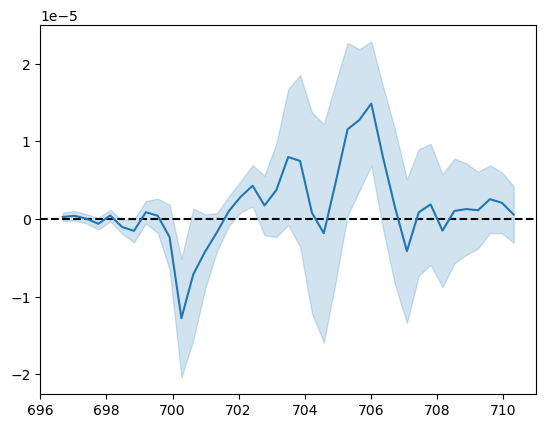

In [19]:
with h5py.File('./avg/Run0112to0145.h5', 'r') as f:
    diff = f['PFY_on_mean'][:] - f['PFY_off_mean'][:]
    energy = f['scanvar_on'][:]
    dPFYerr = np.sqrt(f['PFY_on_std'][:]**2+f['PFY_off_std'][:]**2)
    plt.figure()
    plt.axhline(0, color = 'black', linestyle = '--')
    plt.plot(energy, diff)
    plt.fill_between(f['scanvar_off'],(f['PFY_on_mean'][:]-f['PFY_off_mean'][:])-dPFYerr,(f['PFY_on_mean'][:]-f['PFY_off_mean'][:])+dPFYerr,alpha=0.2,color='tab:blue')
    plt.show()
                
